**NAME: HIMANI DALVI**



**ROLL NO.: 07**


**BATCH: B3-B1**


**SI-PROJECT**

In [1]:
#Video Game Sales Analysis#

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
#PR1 - WEB SCRAPING (collecting video game data from a website)

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://en.wikipedia.org/wiki/List_of_best-selling_video_games"
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.text)
print("Heading:", soup.find("h1").text)

In [ ]:
#Extract the best-selling games table
table = soup.find("table", class_="wikitable")
header = [th.get_text(strip=True) for th in table.find("tr").find_all("th")]
print(header)

n = len(header) - 1     # all columns except Rank
games = []

for row in table.find_all("tr")[1:]:
    cols = [c.get_text(strip=True) for c in row.find_all(["th", "td"])]
    if len(cols) >= n:
        games.append(cols[-n:])     # tied games have no Rank cell, so take the last n cells

scraped = pd.DataFrame(games, columns=header[1:])
print("Games scraped:", len(scraped))

In [ ]:
#Clean the scraped data and save to CSV
scraped = scraped.rename(columns={header[1]: "Title", header[2]: "Sales"})
scraped["Sales"] = scraped["Sales"].str.replace(r"\[.*?\]", "", regex=True)   # remove [a] notes
scraped["Sales"] = pd.to_numeric(scraped["Sales"], errors="coerce")
scraped = scraped.dropna(subset=["Sales"])

scraped.to_csv("best_selling_games.csv", index=False)
print(scraped[["Title", "Sales"]].head(10))
print("Average sales of these top games (millions):", scraped["Sales"].mean())

We scraped the Wikipedia list of best-selling video games using requests and BeautifulSoup and saved it as best_selling_games.csv.
For the main analysis we use the Kaggle Video Game Sales dataset (vgsales.csv), which was itself scraped from vgchartz.com.

In [7]:
#LOAD DATASET (Kaggle: Video Game Sales, vgsales.csv)

In [8]:
df = pd.read_csv("vgsales.csv")
print(df.shape)
df.head()

(16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [9]:
#PREPROCESSING

In [10]:
print(df.columns)

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='str')


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [12]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


In [13]:
#CLEANING

In [14]:
df = df.dropna()

In [15]:
df["Year"] = df["Year"].astype(int)
df = df.drop_duplicates()

In [16]:
print("Clean data shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())

Clean data shape: (16291, 11)
Missing values left: 0


In [17]:
#summary

In [18]:
print("Total games:", len(df))
print("Numerical columns: Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales")
print("Categorical columns: Platform, Genre, Publisher")
print()
print(df["Genre"].value_counts())

Total games: 16291
Numerical columns: Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales
Categorical columns: Platform, Genre, Publisher

Genre
Action          3251
Sports          2304
Misc            1686
Role-Playing    1470
Shooter         1282
Adventure       1274
Racing          1225
Platform         875
Simulation       848
Fighting         836
Strategy         670
Puzzle           570
Name: count, dtype: int64


In [19]:
#PR2

In [20]:
#Global Sales statistics

In [21]:
g = df["Global_Sales"]
print("Mean=", g.mean())
print("Median=", g.median())
print("Mode=", g.mode()[0])
print("Variance=", g.var())
print("Std Dev=", g.std())
print("Range=", g.max() - g.min())
print("IQR=", g.quantile(0.75) - g.quantile(0.25))

Mean= 0.5409103185808115
Median= 0.17
Mode= 0.02
Variance= 2.4565688029450854
Std Dev= 1.5673445067837146
Range= 82.72999999999999
IQR= 0.42


In [22]:
df[["Year", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].describe()

,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
mean,2006.405561,0.265647,0.147731,0.078833,0.048426,0.540910
std,5.832412,0.822432,0.509303,0.311879,0.190083,1.567345
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [23]:
#Quartiles, min, max and skewness
Q1 = g.quantile(0.25)
Q2 = g.quantile(0.50)
Q3 = g.quantile(0.75)
print("Q1 =", Q1, " Q2 =", Q2, " Q3 =", Q3)
print("Min =", g.min(), " Max =", g.max())
print("Skewness =", g.skew())

Q1 = 0.06  Q2 = 0.17  Q3 = 0.48
Min = 0.01  Max = 82.74
Skewness = 17.304311675183435


In [24]:
#Genre-wise average sales

In [25]:
print(df.groupby("Genre")["Global_Sales"].mean().sort_values(ascending=False))

Genre
Platform        0.947577
Shooter         0.800468
Role-Playing    0.628456
Racing          0.593273
Sports          0.568247
Fighting        0.531160
Action          0.529942
Misc            0.468488
Simulation      0.459882
Puzzle          0.424930
Strategy        0.258612
Adventure       0.184137
Name: Global_Sales, dtype: float64


In [26]:
#Interpretation

The mean of Global Sales is higher than the median, so the data is right-skewed.
A few hit games sell very high, while most games sell little.
The standard deviation is large, so sales vary a lot.
Q1 = 0.06, Q2 = 0.17 and Q3 = 0.48 million, so 75% of games sell less than half a million copies.
Skewness is 17.3, which confirms a very strong right skew.

In [27]:
#Histogram of Global Sales

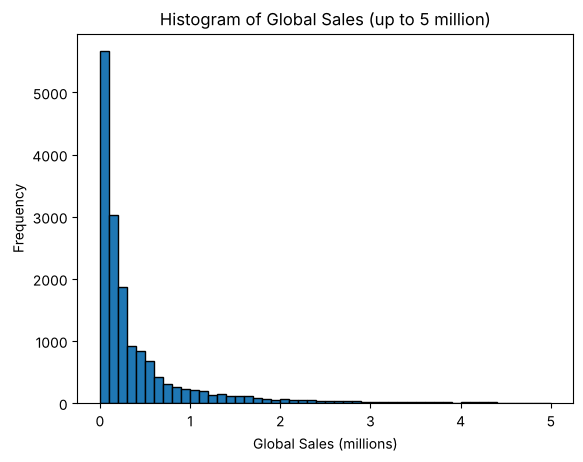

In [28]:
plt.hist(df["Global_Sales"], bins=50, edgecolor="black", range=(0, 5))
plt.title("Histogram of Global Sales (up to 5 million)")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Frequency")
plt.show()

In [29]:
#Boxplot of Sales by Genre

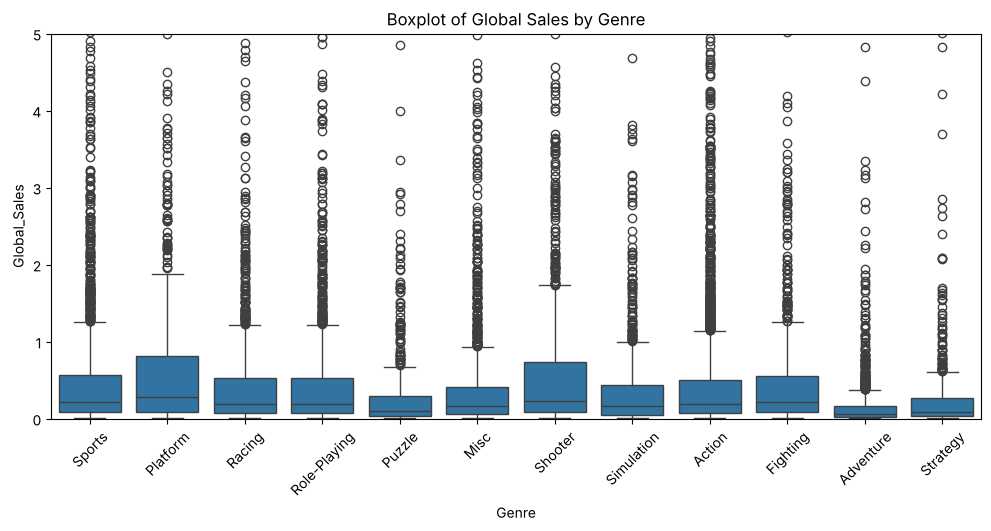

In [30]:
plt.figure(figsize=(12, 5))
sns.boxplot(x="Genre", y="Global_Sales", data=df)
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.title("Boxplot of Global Sales by Genre")
plt.show()

In [31]:
#Top 10 Games by Sales

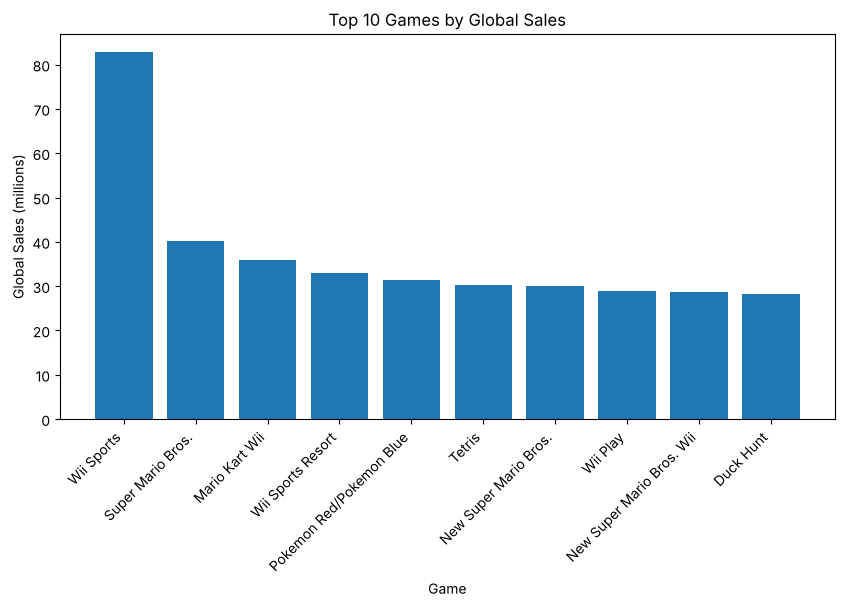

In [32]:
top10 = df.nlargest(10, "Global_Sales")
plt.figure(figsize=(10, 5))
plt.bar(top10["Name"], top10["Global_Sales"])
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Games by Global Sales")
plt.xlabel("Game")
plt.ylabel("Global Sales (millions)")
plt.show()

In [33]:
#Region-wise Sales Share

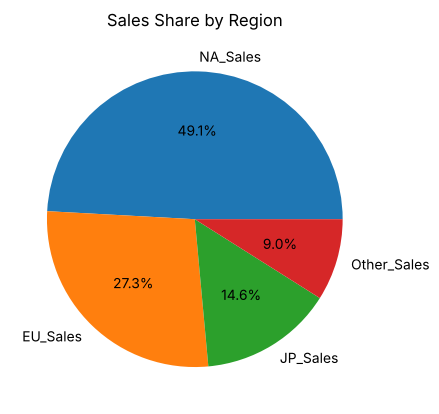

In [34]:
region = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
plt.pie(region, labels=region.index, autopct="%1.1f%%")
plt.title("Sales Share by Region")
plt.show()

In [35]:
#Scatter Plot

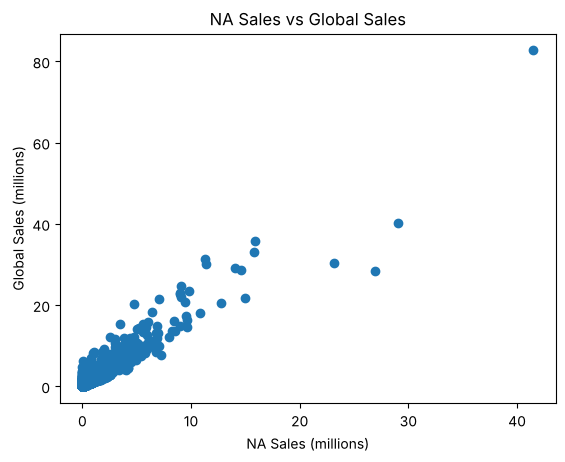

In [36]:
plt.scatter(df["NA_Sales"], df["Global_Sales"])
plt.title("NA Sales vs Global Sales")
plt.xlabel("NA Sales (millions)")
plt.ylabel("Global Sales (millions)")
plt.show()

In [37]:
#Line Chart

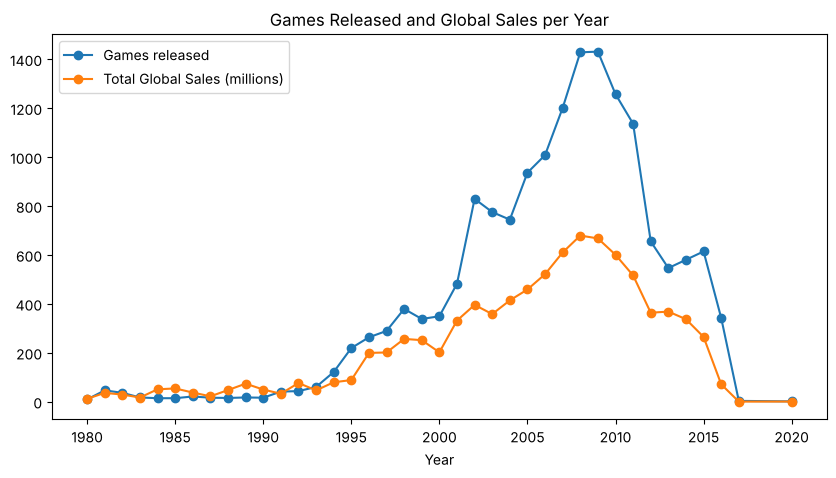

Year with most games: 2009
Year with highest sales: 2008


In [38]:
per_year = df.groupby("Year")["Global_Sales"].agg(["count", "sum"])

plt.figure(figsize=(10, 5))
plt.plot(per_year.index, per_year["count"], marker="o", label="Games released")
plt.plot(per_year.index, per_year["sum"], marker="o", label="Total Global Sales (millions)")
plt.title("Games Released and Global Sales per Year")
plt.xlabel("Year")
plt.legend()
plt.show()

print("Year with most games:", per_year["count"].idxmax())
print("Year with highest sales:", per_year["sum"].idxmax())

In [39]:
#Interpretation

The histogram is right skewed: most games sell less than 1 million copies.
The boxplot shows many outliers, which are the hit games.
North America has the largest share of sales.
NA Sales and Global Sales increase together.
The line chart shows that game releases and sales grew fast after 1995 and peaked in 2008 and 2009, then dropped.
The dataset was collected around 2016, so the last few years look very low because their data is incomplete.

In [40]:
#Sampling and Distributions

In [41]:
#Sampling methods

In [42]:
np.random.seed(1)

# Simple random sampling
sample1 = df.sample(n=200, random_state=1)

# With replacement
sample2 = df.sample(n=200, replace=True, random_state=1)

# Fraction sampling (10%)
sample3 = df.sample(frac=0.10, random_state=1)

# Systematic sampling (every 50th row)
sample4 = df.iloc[::50]

# Stratified sampling (20 games from each Genre)
sample5 = df.groupby("Genre").sample(n=20, random_state=1)

# Cluster sampling (2 random Platforms)
clusters = np.random.choice(df["Platform"].unique(), 2)
print("Selected clusters:", clusters)
sample6 = df[df["Platform"].isin(clusters)]

Selected clusters: ['PS3' 'N64']


In [43]:
#Compare population and samples

In [44]:
comparison = pd.DataFrame({
    "Statistics": ["Size", "Mean", "Median", "Std Dev"],
    "Population": [len(df), df["Global_Sales"].mean(), df["Global_Sales"].median(), df["Global_Sales"].std()],
    "Simple Random": [len(sample1), sample1["Global_Sales"].mean(), sample1["Global_Sales"].median(), sample1["Global_Sales"].std()],
    "Systematic": [len(sample4), sample4["Global_Sales"].mean(), sample4["Global_Sales"].median(), sample4["Global_Sales"].std()],
    "Stratified": [len(sample5), sample5["Global_Sales"].mean(), sample5["Global_Sales"].median(), sample5["Global_Sales"].std()],
    "Cluster": [len(sample6), sample6["Global_Sales"].mean(), sample6["Global_Sales"].median(), sample6["Global_Sales"].std()]
})
comparison

,Statistics,Population,Simple Random,Systematic,Stratified,Cluster
0,Size,16291.000000,200.000000,326.000000,240.000000,1620.000000
1,Mean,0.540910,0.537650,0.750613,0.505417,0.720716
2,Median,0.170000,0.155000,0.170000,0.165000,0.280000
3,Std Dev,1.567345,1.293914,4.670222,1.128630,1.404539


In [45]:
#Percentage error in mean

In [46]:
population_mean = df["Global_Sales"].mean()
sample_mean = sample1["Global_Sales"].mean()

error = abs((sample_mean - population_mean) / population_mean) * 100
print("Percentage Error in Mean:", error)

Percentage Error in Mean: 0.6027466049022063


In [47]:
#Normal distribution

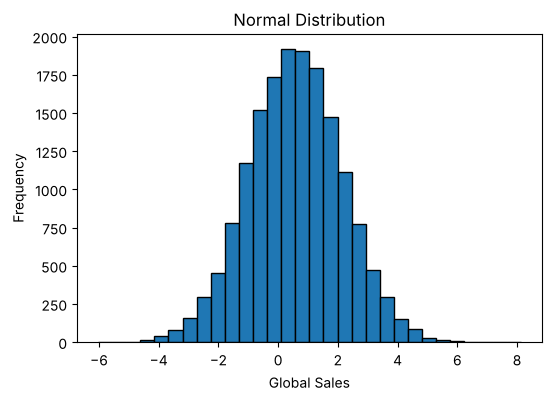

In [48]:
M = df["Global_Sales"].mean()
S = df["Global_Sales"].std()

norm = np.random.normal(M, S, len(df))

plt.figure(figsize=(6, 4))
plt.hist(norm, bins=30, edgecolor="black")
plt.title("Normal Distribution")
plt.xlabel("Global Sales")
plt.ylabel("Frequency")
plt.show()

In [49]:
#Binomial distribution

Probability of a hit game: 0.1263274200478792


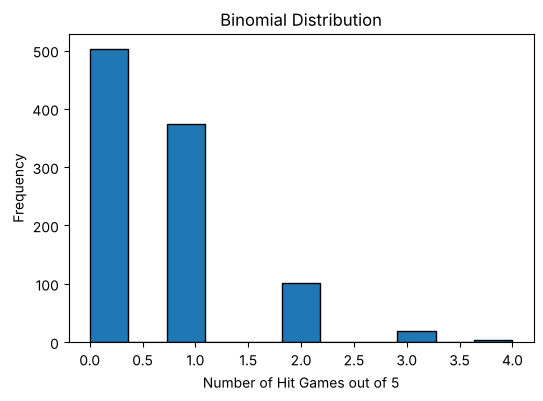

In [50]:
p = (df["Global_Sales"] >= 1).mean()
print("Probability of a hit game:", p)

binomial = np.random.binomial(n=5, p=p, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(binomial, bins=11, edgecolor="black")
plt.title("Binomial Distribution")
plt.xlabel("Number of Hit Games out of 5")
plt.ylabel("Frequency")
plt.show()

In [51]:
#Poisson distribution

Lambda = 417.71794871794873


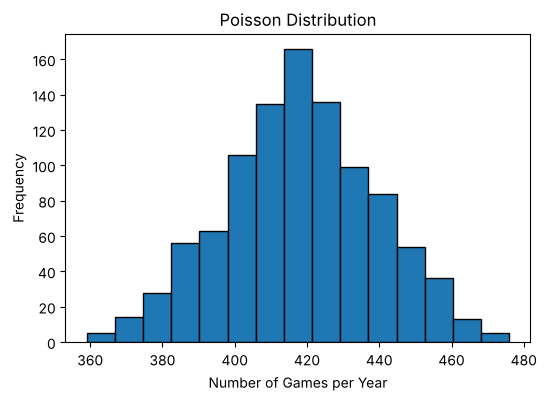

In [52]:
lambda_value = len(df) / df["Year"].nunique()
print("Lambda =", lambda_value)

poisson = np.random.poisson(lam=lambda_value, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(poisson, bins=15, edgecolor="black")
plt.title("Poisson Distribution")
plt.xlabel("Number of Games per Year")
plt.ylabel("Frequency")
plt.show()

In [53]:
#Binomial probability using scipy
from scipy.stats import binom

p_hit = (df["Global_Sales"] >= 1).mean()
print("P(exactly 1 hit game out of 5) =", binom.pmf(1, 5, p_hit))
print("P(no hit game out of 5) =", binom.pmf(0, 5, p_hit))

P(exactly 1 hit game out of 5) = 0.3680124012911597
P(no hit game out of 5) = 0.5090301756634669


In [54]:
#Uniform distribution

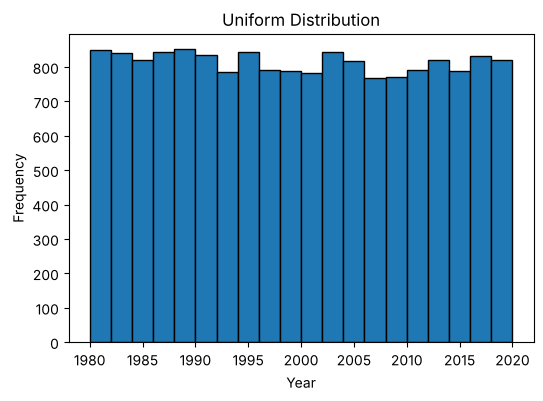

Uniform Mean Year: 1999.8390985030155
Actual Mean Year: 2006.4055613528942


In [55]:
#If games were released equally in every year
uniform = np.random.uniform(df["Year"].min(), df["Year"].max(), len(df))

plt.figure(figsize=(6, 4))
plt.hist(uniform, bins=20, edgecolor="black")
plt.title("Uniform Distribution")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.show()

print("Uniform Mean Year:", uniform.mean())
print("Actual Mean Year:", df["Year"].mean())

In [56]:
#Distribution comparison: population vs samples

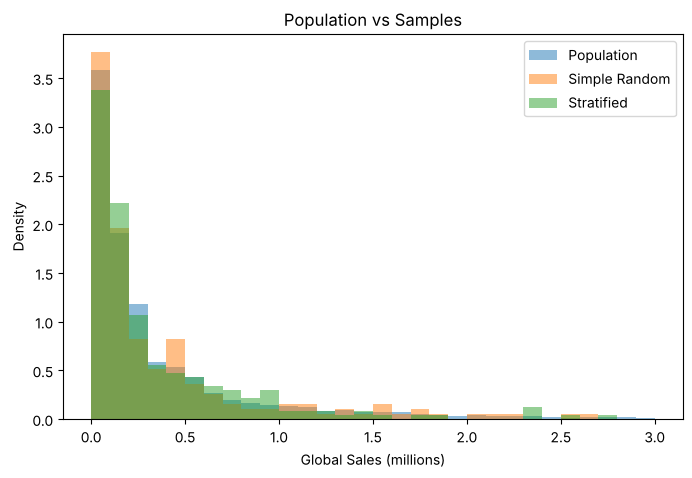

In [57]:
plt.figure(figsize=(8, 5))
plt.hist(df["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Population")
plt.hist(sample1["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Simple Random")
plt.hist(sample5["Global_Sales"], bins=30, range=(0, 3), alpha=0.5, density=True, label="Stratified")
plt.title("Population vs Samples")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Density")
plt.legend()
plt.show()

In [58]:
#Probability distribution

Year
2009    0.087840
2010    0.077159
2011    0.069732
2012    0.040206
2013    0.033515
2014    0.035602
2015    0.037690
2016    0.020993
2017    0.000184
2020    0.000061
Name: proportion, dtype: float64


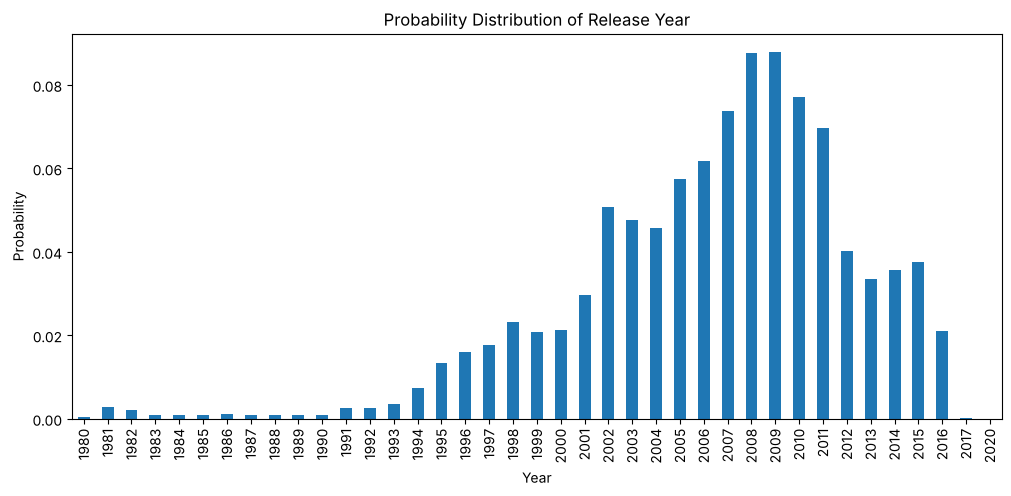

In [59]:
probability = df["Year"].value_counts(normalize=True).sort_index()
print(probability.tail(10))

probability.plot(kind="bar", figsize=(12, 5))
plt.title("Probability Distribution of Release Year")
plt.xlabel("Year")
plt.ylabel("Probability")
plt.show()

In [60]:
#Cumulative probability distribution (CDF)

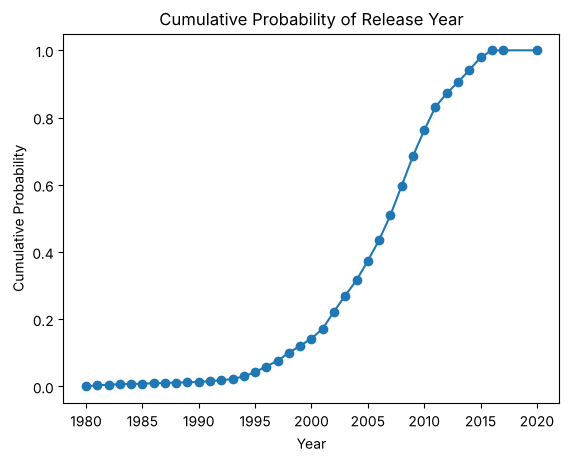

P(game released in or before 2005) = 0.3737646553311645


In [61]:
cdf = probability.cumsum()

plt.plot(cdf.index, cdf.values, marker="o")
plt.title("Cumulative Probability of Release Year")
plt.xlabel("Year")
plt.ylabel("Cumulative Probability")
plt.show()

print("P(game released in or before 2005) =", cdf[2005])

In [62]:
#Interpretation

Sample means are close to the population mean, so sampling works well.
Stratified sampling covers all genres equally.
The real sales data is right skewed, so it is not normal.
The binomial chart shows how many hit games we get in 5 random games.
For a set of 5 random games, there is a 51% chance of getting no hit game and a 37% chance of exactly one.
The uniform mean year (about 2000) is far from the actual mean year (2006), so games are not released evenly across years.
The probability distribution shows 2008 and 2009 are the most likely release years (about 8.8% each).
The CDF shows that only 37% of games were released in or before 2005, and about half of all games come from 2005 to 2011.
The population vs samples plot shows that the simple random and stratified samples follow the same shape as the population.

In [63]:
#CLT and Point Estimation

In [64]:
#Population

Population Mean: 0.5409103185808115
Population Std: 1.5672964014322988


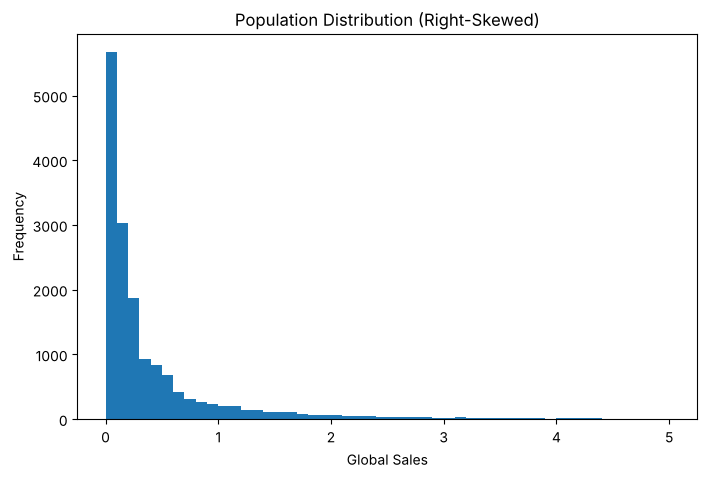

In [65]:
population = df["Global_Sales"].values
population_mean = np.mean(population)
population_std = np.std(population)

print("Population Mean:", population_mean)
print("Population Std:", population_std)

plt.figure(figsize=(8, 5))
plt.hist(population, bins=50, range=(0, 5))
plt.title("Population Distribution (Right-Skewed)")
plt.xlabel("Global Sales")
plt.ylabel("Frequency")
plt.show()

In [66]:
#Repeated sampling, n = 30

In [67]:
np.random.seed(50)
sample_size = 30
number_of_sample = 1000
sample_means = []

for i in range(number_of_sample):
    sample = np.random.choice(population, size=sample_size)
    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

In [68]:
#Distribution of sample means

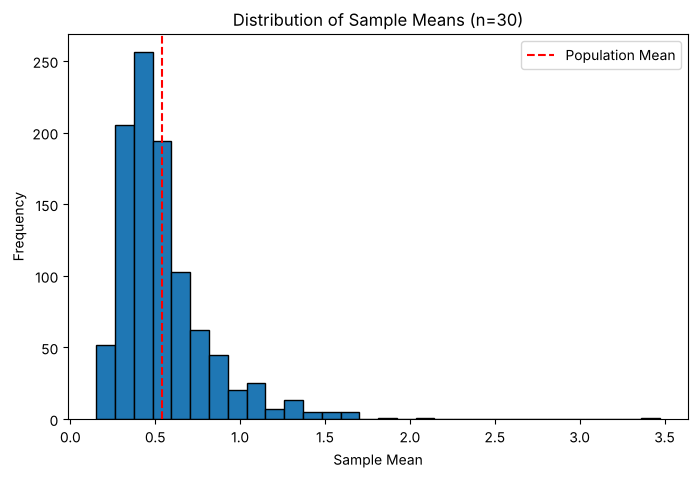

In [69]:
plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.axvline(population_mean, linestyle="--", color="red", label="Population Mean")
plt.title("Distribution of Sample Means (n=30)")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [70]:
#CLT results and standard error

In [71]:
observed_se = np.std(sample_means, ddof=1)
theoretical_se = population_std / np.sqrt(sample_size)

print("CLT Results")
print("Population Mean:", population_mean)
print("Mean of Sample Means:", np.mean(sample_means))
print("Observed Standard Error:", observed_se)
print("Theoretical Standard Error:", theoretical_se)

CLT Results
Population Mean: 0.5409103185808115
Mean of Sample Means: 0.5462946666666667
Observed Standard Error: 0.2778881483520845
Theoretical Standard Error: 0.28614786445371404


In [72]:
#Effect of sample size

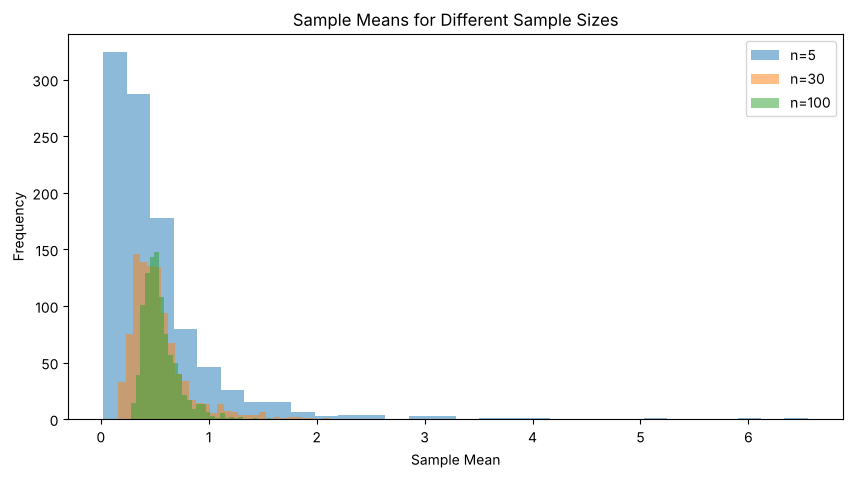

In [73]:
sizes = [5, 30, 100]
plt.figure(figsize=(10, 5))

for n in sizes:
    means = [np.mean(np.random.choice(population, size=n)) for i in range(1000)]
    plt.hist(means, bins=30, alpha=0.5, label=f"n={n}")

plt.title("Sample Means for Different Sample Sizes")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [74]:
#Point estimation

In [75]:
sample = df["Global_Sales"].sample(n=50, random_state=42)

estimated_mean = sample.mean()
estimated_variance = sample.var()
estimated_std = sample.std()

print("Point Estimation")
print("Estimated Mean:", estimated_mean)
print("Estimated Variance:", estimated_variance)
print("Estimated Standard Deviation:", estimated_std)

error = abs(estimated_mean - population_mean)
print("Estimation Error:", error)

Point Estimation
Estimated Mean: 1.4851999999999999
Estimated Variance: 23.013817306122448
Estimated Standard Deviation: 4.797271860768623
Estimation Error: 0.9442896814191883


In [76]:
#Skewness: population vs sample means

In [77]:
print("Population Skewness:", pd.Series(population).skew())
print("Sample Means Skewness (n=30):", pd.Series(sample_means).skew())

Population Skewness: 17.304311675183435
Sample Means Skewness (n=30): 2.6475839627405247


In [78]:
#Bootstrap

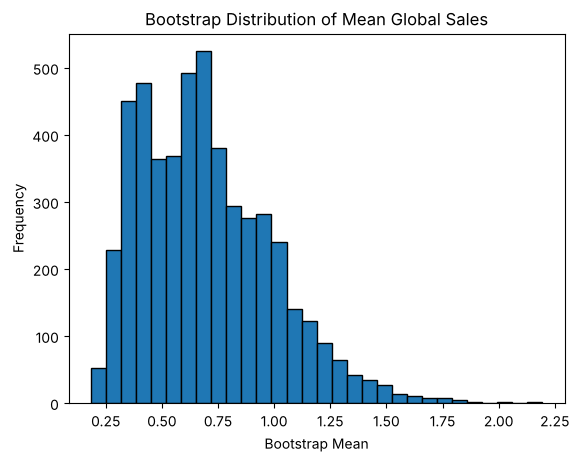

Population Mean: 0.5409103185808115
Bootstrap Estimate: 0.6968666800000001


In [79]:
#Estimate the mean from ONE sample of 50 games by resampling it 5000 times
sample = df["Global_Sales"].sample(n=50, random_state=1)
bootstrap_means = []

for i in range(5000):
    boot = sample.sample(n=50, replace=True)
    bootstrap_means.append(boot.mean())

plt.hist(bootstrap_means, bins=30, edgecolor="black")
plt.title("Bootstrap Distribution of Mean Global Sales")
plt.xlabel("Bootstrap Mean")
plt.ylabel("Frequency")
plt.show()

print("Population Mean:", population_mean)
print("Bootstrap Estimate:", np.mean(bootstrap_means))

In [80]:
#Sample mean vs sample median as estimators

In [81]:
means = []
medians = []

for i in range(1000):
    s = df["Global_Sales"].sample(n=30, replace=True)
    means.append(s.mean())
    medians.append(s.median())

print("Population Mean:", df["Global_Sales"].mean(), "| Average Sample Mean:", np.mean(means))
print("Population Median:", df["Global_Sales"].median(), "| Average Sample Median:", np.mean(medians))
print("Variance of Mean Estimator:", np.var(means, ddof=1))
print("Variance of Median Estimator:", np.var(medians, ddof=1))

Population Mean: 0.5409103185808115 | Average Sample Mean: 0.5474166666666667
Population Median: 0.17 | Average Sample Median: 0.181935
Variance of Mean Estimator: 0.07134079184740297
Variance of Median Estimator: 0.003934465240240241


In [82]:
#Interpretation

The population is right skewed, but the sample means look normal. This proves the CLT.
The mean of sample means is close to the population mean.
Observed SE is close to theoretical SE.
A bigger sample size gives a narrower spread, so a more accurate estimate.
Skewness drops from 17.3 (population) to 2.6 (sample means), so the sample means are much closer to normal.
The bootstrap estimate (0.70) is above the population mean (0.54) because it only resamples one sample of 50 games, and that sample has a few big hits. Bootstrap can only be as good as the original sample.
The median estimator has a much smaller variance (0.004) than the mean estimator (0.071). For skewed data like game sales, the median is the more stable estimator.

In [83]:
#Confidence Interval

In [84]:
data = df["Global_Sales"]
n = len(data)
sample_mean = data.mean()
sample_std = data.std()

confidence = 0.95
standard_error = sample_std / np.sqrt(n)
t_critical = stats.t.ppf((1 + confidence) / 2, df=n-1)
margin_error = t_critical * standard_error

print("Lower Limit:", sample_mean - margin_error)
print("Upper Limit:", sample_mean + margin_error)

Lower Limit: 0.516840603191793
Upper Limit: 0.56498003396983


We are 95% confident that the true mean Global Sales lies between the lower and upper limit.
The interval is narrow because the sample size is large.
The Z interval (0.5168 to 0.5650) is almost the same as the t interval because the sample size is very large.

In [85]:
#Confidence Interval using Z value
z_critical = stats.norm.ppf((1 + confidence) / 2)
margin_z = z_critical * standard_error

print("Z critical =", z_critical)
print("Lower Limit:", sample_mean - margin_z)
print("Upper Limit:", sample_mean + margin_z)

Z critical = 1.959963984540054
Lower Limit: 0.5168423915955458
Upper Limit: 0.5649782455660772


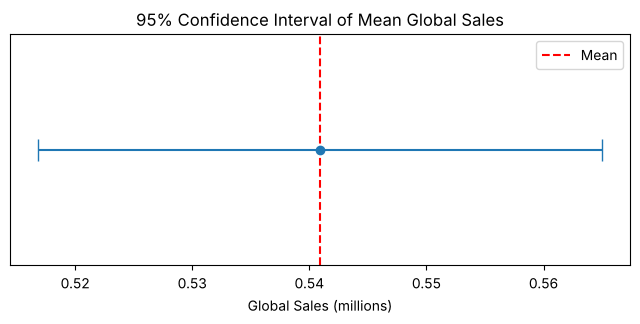

In [86]:
#Confidence Interval plot
plt.figure(figsize=(8, 3))
plt.errorbar(sample_mean, 1, xerr=margin_error, fmt="o", capsize=8)
plt.axvline(sample_mean, color="red", linestyle="--", label="Mean")
plt.yticks([])
plt.title("95% Confidence Interval of Mean Global Sales")
plt.xlabel("Global Sales (millions)")
plt.legend()
plt.show()

In [87]:
#Hypothesis Tests (t-tests)

In [88]:
#One-sample t-test

In [89]:
t, p = stats.ttest_1samp(df["Global_Sales"], 0.5)
print("Sample mean =", df["Global_Sales"].mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Sample mean = 0.5409103185808115
t-statistic = 3.331518791108928
p-value = 0.0008656556627553274
Decision: Reject H0


In [90]:
#Two-sample t-test

In [91]:
action = df[df["Genre"] == "Action"]["Global_Sales"]
sports = df[df["Genre"] == "Sports"]["Global_Sales"]

t, p = stats.ttest_ind(action, sports)
print("Action mean =", action.mean())
print("Sports mean =", sports.mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Action mean = 0.529941556444171
Sports mean = 0.5682465277777778
t-statistic = -0.8669652615704935
p-value = 0.3859985033908565
Decision: Fail to reject H0


In [92]:
#95% Confidence Interval for difference in means (Action - Sports)
diff = action.mean() - sports.mean()
se = np.sqrt(action.var() / len(action) + sports.var() / len(sports))
dof = len(action) + len(sports) - 2

ci = stats.t.interval(0.95, dof, loc=diff, scale=se)
print("Difference in means =", diff)
print("95% CI =", ci)

Difference in means = -0.038304971333606885
95% CI = (np.float64(-0.13315030013350873), np.float64(0.05654035746629496))


In [93]:
#Paired t-test

In [94]:
t, p = stats.ttest_rel(df["NA_Sales"], df["EU_Sales"])
print("NA mean =", df["NA_Sales"].mean())
print("EU mean =", df["EU_Sales"].mean())
print("t-statistic =", t)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

NA mean = 0.26564667607881653
EU mean = 0.14773126266036463
t-statistic = 27.86939914163056
p-value = 5.067184380139175e-167
Decision: Reject H0


In [95]:
#Z-test

In [96]:
#H0: mean Global Sales = 0.5 million
mu = 0.5
z = (df["Global_Sales"].mean() - mu) / (df["Global_Sales"].std() / np.sqrt(len(df)))
p_z = 2 * (1 - stats.norm.cdf(abs(z)))

print("Z-statistic =", z)
print("p-value =", p_z)
print("Decision:", "Reject H0" if p_z < 0.05 else "Fail to reject H0")

Z-statistic = 3.331518791108928
p-value = 0.0008637346850466354
Decision: Reject H0


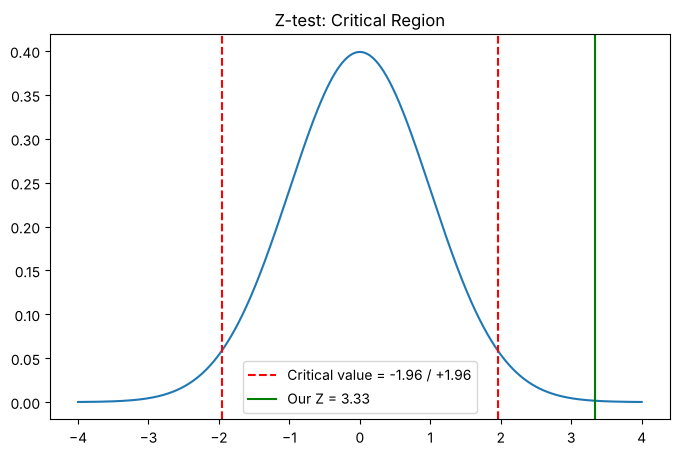

In [97]:
#Normal curve with critical values (alpha = 0.05)
x = np.linspace(-4, 4, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x, stats.norm.pdf(x))
plt.axvline(-1.96, color="red", linestyle="--", label="Critical value = -1.96 / +1.96")
plt.axvline(1.96, color="red", linestyle="--")
plt.axvline(z, color="green", label="Our Z = " + str(round(z, 2)))
plt.title("Z-test: Critical Region")
plt.legend()
plt.show()

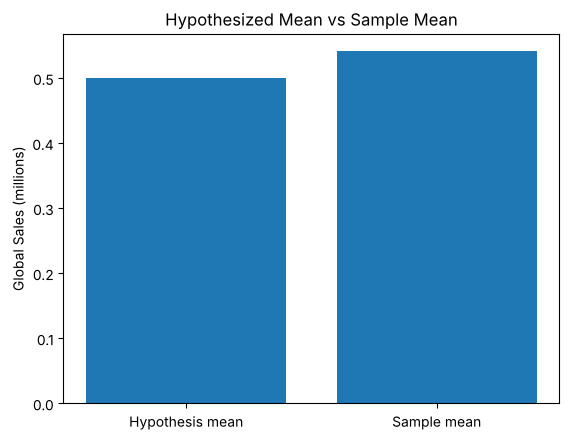

In [98]:
#Hypothesized mean vs sample mean
plt.bar(["Hypothesis mean", "Sample mean"], [mu, df["Global_Sales"].mean()])
plt.title("Hypothesized Mean vs Sample Mean")
plt.ylabel("Global Sales (millions)")
plt.show()

1-sample t-test: H0 says mean Global Sales = 0.5 million. t = 3.33, p = 0.0009 which is less than 0.05, so we reject H0. The mean Global Sales (0.541 million) is significantly different from 0.5 million.
2-sample t-test: H0 says Action and Sports have the same mean sales. p = 0.386 which is more than 0.05, so we fail to reject H0. Action (0.53) and Sports (0.57) sales are not significantly different. The 95% CI for the difference (-0.13 to 0.06) contains 0, which agrees.
Paired t-test: the same games are measured in two regions, so a paired test is used. p is almost 0, so we reject H0. NA sales (0.27) are significantly higher than EU sales (0.15).
Z-test: Z = 3.33 is beyond the critical value 1.96 and p = 0.0009, so we reject H0. This matches the 1-sample t-test.

In [99]:
#ANOVA

In [100]:
groups = [grp["Global_Sales"].values for name, grp in df.groupby("Genre")]
F, p = stats.f_oneway(*groups)

print("F-statistic =", F)
print("p-value =", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

F-statistic = 18.176106122556163
p-value = 1.3358892024482895e-36
Decision: Reject H0


One-way ANOVA: H0 says all genres have the same average sales. F = 18.18 and p is almost 0, so we reject H0. Average sales differ across genres: Platform games sell the most (0.95 million) and Adventure games the least (0.18 million).
Two-way ANOVA (top 5 genres and top 5 platforms): Genre (p = 0.005), Platform (p = 0.000003) and their interaction (p = 0.00003) are all significant. So sales depend on the genre, the platform and also on the combination of both.

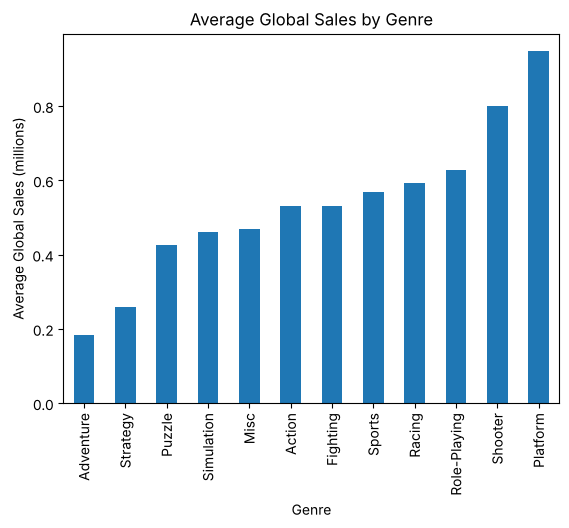

In [101]:
#Average sales by genre
df.groupby("Genre")["Global_Sales"].mean().sort_values().plot(kind="bar")
plt.title("Average Global Sales by Genre")
plt.ylabel("Average Global Sales (millions)")
plt.show()

In [102]:
#Two-way ANOVA

In [103]:
#Effect of Genre, Platform and their interaction on Global Sales
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

top5_platforms = df["Platform"].value_counts().head(5).index
top5_genres = df["Genre"].value_counts().head(5).index
data2 = df[df["Platform"].isin(top5_platforms) & df["Genre"].isin(top5_genres)]

model = ols("Global_Sales ~ C(Genre) + C(Platform) + C(Genre):C(Platform)", data=data2).fit()
anova_table = anova_lm(model, typ=2)
print(anova_table)

print("Genre significant?", anova_table["PR(>F)"]["C(Genre)"] < 0.05)
print("Platform significant?", anova_table["PR(>F)"]["C(Platform)"] < 0.05)
print("Interaction significant?", anova_table["PR(>F)"]["C(Genre):C(Platform)"] < 0.05)

                            sum_sq      df         F    PR(>F)
C(Genre)                 56.143947     4.0  3.747378  0.004763
C(Platform)             116.567763     4.0  7.780419  0.000003
C(Genre):C(Platform)    185.987528    16.0  3.103476  0.000028
Residual              19233.394795  5135.0       NaN       NaN
Genre significant? True
Platform significant? True
Interaction significant? True


In [104]:
#Chi-Square Test

In [105]:
top_platforms = df["Platform"].value_counts().head(5).index
top_genres = df["Genre"].value_counts().head(5).index
small = df[df["Platform"].isin(top_platforms) & df["Genre"].isin(top_genres)]

observed = pd.crosstab(small["Genre"], small["Platform"])
print(observed)

chi2, p, dof, expected = stats.chi2_contingency(observed)
print("Chi-Square:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")

Platform       DS  PS2  PS3  Wii  X360
Genre                                 
Action        335  345  373  230   318
Misc          389  218  121  272   122
Role-Playing  196  183  117   35    75
Shooter        42  158  155   61   197
Sports        146  391  210  256   215
Chi-Square: 591.5379997251702
Degrees of freedom: 16
p-value: 1.4248178885745373e-115
Decision: Reject H0


Chi-square test of independence: Chi-square = 591.5, DOF = 16, p is almost 0, so we reject H0. Genre and platform are related.
For example, DS has 389 Misc games (expected 241), X360 has 197 Shooters (expected 110) and Wii has only 35 Role-Playing games (expected 100).
Goodness of fit: p is almost 0, so games are not equally spread across the top 5 genres. Action has far more games than the others.

In [106]:
#Expected frequencies
print(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1))

#Degree of freedom by formula
print("DOF = (rows - 1) x (columns - 1) =", (observed.shape[0] - 1) * (observed.shape[1] - 1))

Platform         DS    PS2    PS3    Wii   X360
Genre                                          
Action        343.8  401.8  302.8  265.0  287.6
Misc          240.9  281.6  212.2  185.7  201.6
Role-Playing  130.1  152.1  114.6  100.3  108.9
Shooter       131.6  153.8  115.9  101.5  110.1
Sports        261.5  305.7  230.4  201.6  218.8
DOF = (rows - 1) x (columns - 1) = 16


In [107]:
#Chi-Square goodness of fit

In [108]:
#H0: games are equally spread across the top 5 genres
from scipy.stats import chisquare

genre_counts = df["Genre"].value_counts().head(5)
print(genre_counts)

chi2_gof, p_gof = chisquare(genre_counts)
print("Chi-Square:", chi2_gof)
print("p-value:", p_gof)
print("Decision:", "Reject H0" if p_gof < 0.05 else "Fail to reject H0")

Genre
Action          3251
Sports          2304
Misc            1686
Role-Playing    1470
Shooter         1282
Name: count, dtype: int64
Chi-Square: 1277.1075753027121
p-value: 3.0583747530234793e-275
Decision: Reject H0


In [109]:
#Correlation

In [110]:
pairs = [("NA_Sales", "Global_Sales"), ("EU_Sales", "Global_Sales"), ("JP_Sales", "Global_Sales")]

for a, b in pairs:
    x, y = df[a], df[b]
    r, p1 = stats.pearsonr(x, y)
    rho, p2 = stats.spearmanr(x, y)
    print(a, "vs", b)
    print("Covariance =", x.cov(y))
    print("Pearson r =", r, ", p =", p1)
    print("Spearman =", rho, ", p =", p2)
    print("Decision:", "Reject H0 (Significant)" if p1 < 0.05 else "Fail to reject H0")
    print()

NA_Sales vs Global_Sales
Covariance = 1.2133284689867243
Pearson r = 0.9412692156419176 , p = 0.0
Spearman = 0.7949056616713689 , p = 0.0
Decision: Reject H0 (Significant)

EU_Sales vs Global_Sales
Covariance = 0.7210331212630285
Pearson r = 0.9032637339929384 , p = 0.0
Spearman = 0.6966166845015861 , p = 0.0
Decision: Reject H0 (Significant)

JP_Sales vs Global_Sales
Covariance = 0.2995378763140713
Pearson r = 0.6127741711194433 , p = 0.0
Spearman = 0.15506548723574354 , p = 3.2676931515474456e-88
Decision: Reject H0 (Significant)



In [111]:
#Correlation heatmap

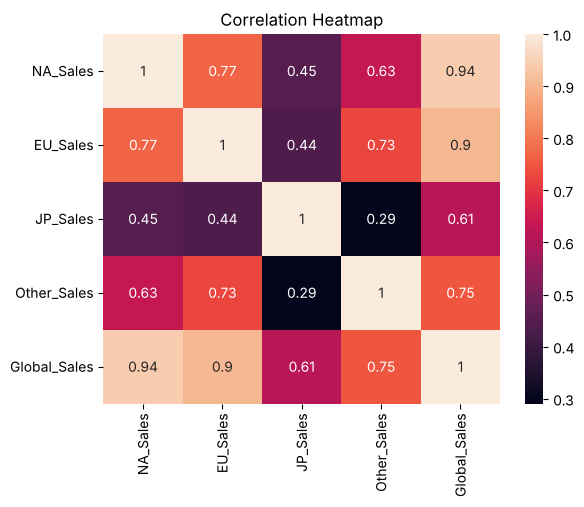

In [112]:
sns.heatmap(df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

All regional sales have a positive correlation with Global Sales.
NA and EU sales have the strongest relation with Global Sales.
All p-values are below 0.05, so the correlations are significant.
NA vs Global Sales has r = 0.94, so the direction is positive and the strength is strong.
All values in the covariance matrix are positive, so all regions move in the same direction.

In [113]:
#Direction and strength
r = df["NA_Sales"].corr(df["Global_Sales"])
print("Correlation (NA vs Global) =", r)
print("Direction:", "Positive" if r > 0 else "Negative")
print("Strength:", "Strong" if abs(r) >= 0.7 else "Moderate" if abs(r) >= 0.3 else "Weak")

Correlation (NA vs Global) = 0.9412692156419163
Direction: Positive
Strength: Strong


In [114]:
#Covariance matrix
df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].cov()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,0.676395,0.322077,0.115754,0.099194,1.213328
EU_Sales,0.322077,0.259389,0.069315,0.070309,0.721033
JP_Sales,0.115754,0.069315,0.097269,0.017225,0.299538
Other_Sales,0.099194,0.070309,0.017225,0.036131,0.222837
Global_Sales,1.213328,0.721033,0.299538,0.222837,2.456569


In [115]:
#PR7 - PART A: REGRESSION (Predict Global Sales from NA Sales)

In [116]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [117]:
X = df[["NA_Sales"]]      #Independent variable
Y = df["Global_Sales"]    #Dependent variable

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("Training Sample:", len(X_train))
print("Testing Sample:", len(X_test))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Training Sample: 13032
Testing Sample: 3259


In [118]:
#Train all 5 models and compare
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
}

results = []
for name, m in models.items():
    m.fit(X_train, Y_train)
    pred = m.predict(X_test)
    mae = mean_absolute_error(Y_test, pred)
    mse = mean_squared_error(Y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, pred)
    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"])
results_df = results_df.sort_values(by="R2", ascending=False)
results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.209798,0.338439,0.581755,0.920888
1,Ridge Regression,0.209805,0.338489,0.581798,0.920876
2,Lasso Regression,0.220954,0.406735,0.637758,0.904923
3,Decision Tree,0.222789,0.885035,0.940763,0.793118
4,Random Forest,0.216458,0.971135,0.985462,0.772992


In [119]:
#Linear regression equation
lin = models["Linear Regression"]
print("Intercept:", lin.intercept_)
print("Slope:", lin.coef_[0])
print("Equation: Global Sales =", round(lin.intercept_, 2), "+", round(lin.coef_[0], 2), "* NA Sales (scaled)")

Intercept: 0.5340323818293431
Slope: 1.3162874892064484
Equation: Global Sales = 0.53 + 1.32 * NA Sales (scaled)


In [120]:
#Actual vs predicted (first 5 test games)
prediction_df = pd.DataFrame({"Actual": Y_test.values[:5]})
for name, m in models.items():
    prediction_df[name] = m.predict(X_test[:5]).round(2)
prediction_df

,Actual,Linear Regression,Ridge Regression,Lasso Regression,Decision Tree,Random Forest
0,0.57,0.98,0.98,0.95,0.96,0.97
1,0.07,0.08,0.08,0.11,0.12,0.12
2,0.19,0.08,0.08,0.11,0.12,0.12
3,0.67,0.84,0.84,0.82,0.72,0.76
4,0.22,0.36,0.36,0.37,0.36,0.33


In [121]:
#Best model
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Best Model:", best_model_name)

Best Model: Linear Regression


In [122]:
#Save and load the model
import joblib
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")

model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")

Linear Regression is the best regression model with R2 = 0.92 and RMSE = 0.58. Ridge gives almost the same result.
Lasso is a little lower (R2 = 0.90). Decision Tree (0.79) and Random Forest (0.77) are lower because a few huge hit games are hard to predict with trees.
Example: a game that sells 1 million copies in North America is predicted to sell about 1.82 million copies worldwide.

In [123]:
#PR7 - PART B: CLASSIFICATION (Will the game be a HIT?)

Hit
0    14233
1     2058
Name: count, dtype: int64


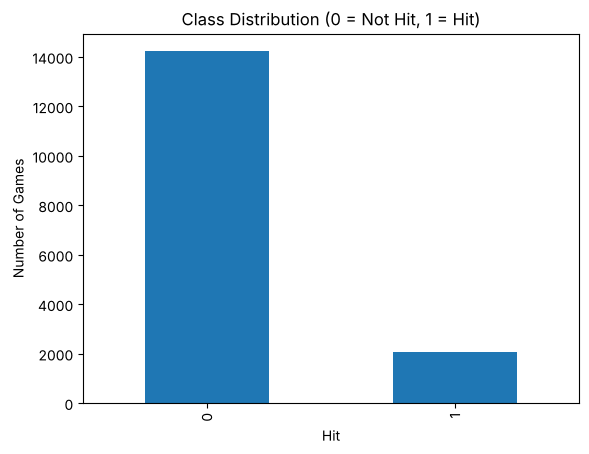

In [124]:
#Target: Hit = 1 if Global Sales >= 1 million, else 0
df["Hit"] = (df["Global_Sales"] >= 1).astype(int)
print(df["Hit"].value_counts())

df["Hit"].value_counts().plot(kind="bar")
plt.title("Class Distribution (0 = Not Hit, 1 = Hit)")
plt.xlabel("Hit")
plt.ylabel("Number of Games")
plt.show()

In [125]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [126]:
Xc = df[["NA_Sales"]]     #Input feature
yc = df["Hit"]            #Target (0 or 1)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print("Training Sample:", len(Xc_train))
print("Testing Sample:", len(Xc_test))

scaler_c = StandardScaler()
Xc_train = scaler_c.fit_transform(Xc_train)
Xc_test = scaler_c.transform(Xc_test)

Training Sample: 13032
Testing Sample: 3259


In [127]:
#Train 4 classification models and compare
classifiers = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

c_results = []
for name, c in classifiers.items():
    c.fit(Xc_train, yc_train)
    pred = c.predict(Xc_test)
    c_results.append([name,
                      accuracy_score(yc_test, pred),
                      precision_score(yc_test, pred),
                      recall_score(yc_test, pred),
                      f1_score(yc_test, pred)])

c_results_df = pd.DataFrame(c_results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"])
c_results_df = c_results_df.sort_values(by="F1-Score", ascending=False)
c_results_df

,Model,Accuracy,Precision,Recall,F1-Score
2,Decision Tree,0.957963,0.887324,0.764563,0.821382
3,Random Forest,0.957349,0.880223,0.766990,0.819715
0,Logistic Regression,0.958269,0.915663,0.737864,0.817204
1,KNN,0.949371,0.840220,0.740291,0.787097


Best Classification Model: Decision Tree
[[2807   40]
 [  97  315]]


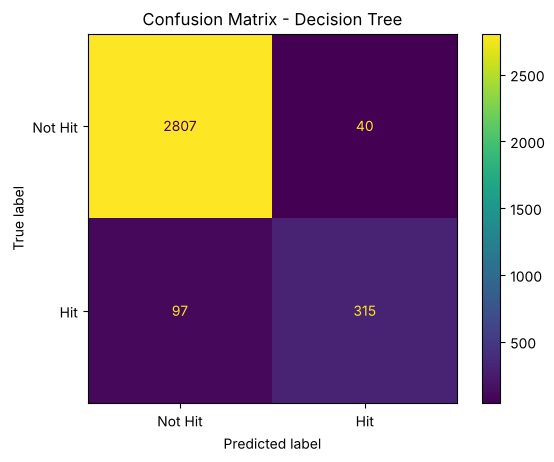

In [128]:
#Best classification model (chosen by F1-Score)
best_clf_name = c_results_df.iloc[0]["Model"]
best_clf = classifiers[best_clf_name]
print("Best Classification Model:", best_clf_name)

cm = confusion_matrix(yc_test, best_clf.predict(Xc_test))
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Not Hit", "Hit"]).plot()
plt.title("Confusion Matrix - " + best_clf_name)
plt.show()

In [129]:
#Save and load the classification model
joblib.dump(best_clf, "best_classifier.pkl")
joblib.dump(scaler_c, "scaler_classifier.pkl")

clf = joblib.load("best_classifier.pkl")
scaler_c = joblib.load("scaler_classifier.pkl")

Only 12.6% of games are hits (2058 out of 16291), so the classes are imbalanced. A model that always says "Not Hit" would already get about 87% accuracy, so accuracy alone can be misleading. That is why we choose the best model using F1-Score.
All 4 models have accuracy between 95% and 96%. Decision Tree has the best F1-Score (0.82), with precision 0.89 and recall 0.76.
Confusion matrix: 2807 non-hit games and 315 hit games are predicted correctly. 40 games were wrongly called hits and 97 real hits were missed.
Most of the missed hits (84%) sold more in Japan and Europe than in North America. The model only looks at NA Sales, so it cannot catch these games.

In [130]:
def predict_game(na_sales):
    x = pd.DataFrame({"NA_Sales": [na_sales]})
    sales = model.predict(scaler.transform(x))[0]
    hit = clf.predict(scaler_c.transform(x))[0]
    result = "Predicted Global Sales: " + str(round(sales, 2)) + " million copies\n"
    result = result + "Prediction: " + ("HIT game" if hit == 1 else "NOT a hit")
    return result

print(predict_game(1.0))     #test: a game that sold 1 million copies in North America
print(predict_game(0.2))

Predicted Global Sales: 1.82 million copies
Prediction: HIT game
Predicted Global Sales: 0.43 million copies
Prediction: NOT a hit


In [131]:
#PR7 - GUI: Gradio app (public link)

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

interface = gr.Interface(
    fn=predict_game,
    inputs=[gr.Number(label="Enter NA Sales (millions):")],
    outputs=gr.Textbox(label="Prediction"),
    title="Video Game Sales and Hit Predictor",
    description="Enter how many million copies a game sold in North America. The app predicts its worldwide sales and whether it will be a hit (1 million+ copies)."
)
interface.launch(share=True)

The Gradio app takes NA Sales as input, uses the best regression model to predict Global Sales and the best classification model to predict Hit or Not Hit. share=True gives a temporary public link that anyone can open.

**CONCLUSION**

Video game sales are highly right skewed: most games sell less than 0.5 million copies and a few hits sell a lot.
North America is the biggest market and has the strongest relation with global sales (r = 0.94).
Sampling and the CLT work well: sample means are close to the population mean and become normal even though the data is skewed.
Genre and platform both have a significant effect on sales, and they are related to each other.
For regression, Linear Regression predicts global sales from NA sales with R2 = 0.92.
For classification, Decision Tree predicts whether a game will be a hit with 95.8% accuracy and an F1-Score of 0.82.
Both best models are saved with joblib and used in a Gradio app with a public link.